In [160]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem

proc_dp = "../../data/proc/nist20"
mol_df = pd.read_pickle(f"{proc_dp}/mol_df.pkl")
mol_df.head()

,smiles,mol_id,mol,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,*C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...,0,<rdkit.Chem.rdchem.Mol object at 0x7fbc1bb35210>,,O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...,C47H75*O19,,944.098,943.490255,67,74,0,True,0
1,BrC1=CCN(Cc2ccccc2)CC1,1,<rdkit.Chem.rdchem.Mol object at 0x7fbc1e0f3d30>,PMICKOYXYJSXPC,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-6-8-14(9-7-12)10-11-...,252.155,251.030962,14,15,0,True,0
2,BrC1CCCCCC(Br)C12OCCO2,2,<rdkit.Chem.rdchem.Mol object at 0x7fbc1aa51e40>,OQCIVOUQHXUSEL,C1CCCC2(CCC1)OCCO2,C10H16Br2O2,InChI=1S/C10H16Br2O2/c11-8-4-2-1-3-5-9(12)10(8...,328.044,325.951704,14,15,0,True,0
3,BrC1CCN(Cc2ccccc2)C1,3,<rdkit.Chem.rdchem.Mol object at 0x7fbc1aa52bb0>,VOXJTPBOJBQGSL,c1ccc(CN2CCCC2)cc1,C11H14BrN,InChI=1S/C11H14BrN/c12-11-6-7-13(9-11)8-10-4-2...,240.144,239.030962,13,14,0,True,0
4,BrC=C(c1ccccc1)c1ccccc1,4,<rdkit.Chem.rdchem.Mol object at 0x7fbc1aa530b0>,QRDVTIMUEDYLOC,C=C(c1ccccc1)c1ccccc1,C14H11Br,InChI=1S/C14H11Br/c15-11-14(12-7-3-1-4-8-12)13...,259.146,258.004412,15,16,0,True,0


In [180]:
from rdkit import Chem
from rdkit.Chem import Draw
from copy import deepcopy

def draw_highlighted_substructure(mol, atom_ids):
    """
    Visualizes molecule with highlighted atoms and bonds between them.
    """
    local_mol = deepcopy(mol)
    
    # Clear existing atom map numbers
    for atom in local_mol.GetAtoms():
        if atom.HasProp("molAtomMapNumber"):
            atom.ClearProp("molAtomMapNumber")
    
    # Set atom map numbers for highlighted atoms
    for idx in atom_ids:
        atom = local_mol.GetAtomWithIdx(idx)
        atom.SetProp("molAtomMapNumber", str(idx))
    
    # Find bonds where both atoms are in atom_ids
    highlight_bonds = []
    atom_id_set = set(atom_ids)
    for bond in local_mol.GetBonds():
        begin = bond.GetBeginAtomIdx()
        end = bond.GetEndAtomIdx()
        if begin in atom_id_set and end in atom_id_set:
            highlight_bonds.append(bond.GetIdx())
    
    # Generate image with highlighted atoms and bonds
    img = Draw.MolToImage(
        local_mol,
        highlightAtoms=atom_ids,
        highlightBonds=highlight_bonds,
        kekulize=True
    )
    return img

from rdkit import Chem
from rdkit.Chem import Draw
from copy import deepcopy

def draw_highlighted_grid(mol, atom_ids_list, n_cols = 7):
    """
    Draws a grid of images of the same molecule, each with a different set of highlighted atoms and bonds.
    atom_ids_list: list of lists of atom indices to highlight in each image.
    n_cols: number of columns in the grid.
    """
    mols = []
    highlight_atom_lists = []
    highlight_bond_lists = []

    for atom_ids in atom_ids_list:
        m = deepcopy(mol)
        # Set atom map numbers for highlighted atoms
        for idx in atom_ids:
            m.GetAtomWithIdx(idx).SetProp("molAtomMapNumber", str(idx))
        mols.append(m)
        highlight_atom_lists.append(atom_ids)
        # Find bonds where both atoms are in atom_ids
        bonds = []
        atom_id_set = set(atom_ids)
        for bond in m.GetBonds():
            begin = bond.GetBeginAtomIdx()
            end = bond.GetEndAtomIdx()
            if begin in atom_id_set and end in atom_id_set:
                bonds.append(bond.GetIdx())
        highlight_bond_lists.append(bonds)

    # Arrange mols, atom highlights, and bond highlights into a matrix with n_cols columns
    def chunk(lst, n):
        """Yield successive n-sized chunks from lst."""
        for i in range(0, len(lst), n):
            yield lst[i:i + n]

    mols_matrix = list(chunk(mols, n_cols))
    highlight_atoms_matrix = list(chunk(highlight_atom_lists, n_cols))
    highlight_bonds_matrix = list(chunk(highlight_bond_lists, n_cols))

    # Draw grid image
    img = Draw.MolsMatrixToGridImage(
        molsMatrix=mols_matrix,
        highlightAtomListsMatrix=highlight_atoms_matrix,
        highlightBondListsMatrix=highlight_bonds_matrix
    )
    return img


In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem


crf1_0 = AllChem.ReactionFromSmarts('[*+0;!H0:0][*+0:1][*+0:2]>>([*+0:0]=[*+0:1].[*+0:2])')
crf1_1 = AllChem.ReactionFromSmarts('[*+0;!H0:0]=[*+0:1][*+0:2]>>([*+0:0]#[*+0:1].[*+0:2])')
crf2_0 = AllChem.ReactionFromSmarts('[*+0:0][*+0:1][*!H0+0:2]>>([*+0:0].[*+0:1]=[*+0:2])')
crf2_1 = AllChem.ReactionFromSmarts('[*+0:0][*+0:1]=[*!H0+0:2]>>([*+0:0].[*+0:1]#[*+0:2])')
crf3_0 = AllChem.ReactionFromSmarts('[*+0:0]1[*+0:1]=[*+0:2][*+0:3][*+0:4][*+0:5]1>>([*+0:0]=[*+0:1][*+0:2]=[*+0:3].[*+0:4]=[*+0:5])')
crf3_1 = AllChem.ReactionFromSmarts('[*+0:0]1[*+0:1]=[*+0:2][*+0:3][*+0:4]=[*+0:5]1>>([*+0:0]=[*+0:1][*+0:2]=[*+0:3].[*+0:4]#[*+0:5])')
crf4_0 = AllChem.ReactionFromSmarts('[*+0:0]=[*+0:1][*+0:2][*+0:3][*+0;!H0:4]>>([*+0:0][*+0:1]=[*+0:2].[*+0:3]=[*+0:4])')
crf5_0 = AllChem.ReactionFromSmarts('[*+0;!H0:0][*+0:1][*+0:2][*+0;!H0:3]>>([*+0:0]=[*+0:1].[*+0:2]=[*+0:3])')
crf6_0 = AllChem.ReactionFromSmarts('[*+0:0]=[*+0:1][*+0:2]=[*+0:3][*+0:4]=[*+0:5][*+0:6]=[*+0:7]>>([*+0:0]=[*+0:7].[*+0:2]=[*+0:3][*+0:4]=[*+0:5][*+0:6]=[*+0:1])')
crf7_0 = AllChem.ReactionFromSmarts('[*+0:0]1[*+0:1][*+0:2][*+0:3][*+0:4][*+0:5]1>>([*+0:0]=[*+0:1].[*+0:2]=[*+0:3].[*+0:4]=[*+0:5])')
crf7_1 = AllChem.ReactionFromSmarts('[*+0:0]1=[*+0:1][*+0:2][*+0:3][*+0:4][*+0:5]1>>([*+0:0]#[*+0:1].[*+0:2]=[*+0:3].[*+0:4]=[*+0:5])')
crf7_2 = AllChem.ReactionFromSmarts('[*+0:0]1=[*+0:1][*+0:2]=[*+0:3][*+0:4][*+0:5]1>>([*+0:0]#[*+0:1].[*+0:2]#[*+0:3].[*+0:4]=[*+0:5])')
crf7_3 = AllChem.ReactionFromSmarts('[*+0:0]1=[*+0:1][*+0:2]=[*+0:3][*+0:4]=[*+0:5]1>>([*+0:0]#[*+0:1].[*+0:2]#[*+0:3].[*+0:4]#[*+0:5])')
crf8_0 = AllChem.ReactionFromSmarts('[*+0;!H0:0][*+0:1]=[*+0:2]>>([*+0:0]=[*+0:1][*+0:2])')
crf8_1 = AllChem.ReactionFromSmarts('[*+0;!H0:0][*+0:1]=[*+0:2][*+0:3]=[*+0:4]>>([*+0:0]=[*+0:1][*+0:2]=[*+0:3][*+0:4])')
crf8_2 = AllChem.ReactionFromSmarts('[*+0;!H0:0][*+0:1]=[*+0:2][*+0:3]=[*+0:4][*+0:5]=[*+0:6]>>([*+0:0]=[*+0:1][*+0:2]=[*+0:3][*+0:4]=[*+0:5][*+0:6])')
crf9_0 = AllChem.ReactionFromSmarts('[*:0]@[C:1](=[O:2])@[*:3]>>([*:0][*:3].[C-:1]#[O+:2])')
crf11_0= AllChem.ReactionFromSmarts('[*+0;!H0:0][*+0;!H0:1]>>([*+0:0]=[*+0:1])')
crf11_1= AllChem.ReactionFromSmarts('[*+0;!H0:0]=[*+0;!H0:1]>>([*+0:0]#[*+0:1])')
crf12_0= AllChem.ReactionFromSmarts('[*+0:0][*+0:1][*+0:2][*+0:3]>>([*+0:0][*+0:3].[*+0:1]=[*+0:2])')
crf12_1= AllChem.ReactionFromSmarts('[*+0:0][*+0:1]=[*+0:2][*+0:3]>>([*+0:0][*+0:3].[*+0:1]#[*+0:2])')
crf13_0= AllChem.ReactionFromSmarts('[*+0:0][C+0:1](=[O+0:2])[OH+0:3]>>([*+0:0].[O+0:2]=[C+0:1]=[O+0:3])')
crf13_1= AllChem.ReactionFromSmarts('[C+0;H1:0](=[O+0:1])[O+0:2][*+0:3]>>([O+0:1]=[C+0:0]=[O+0:2].[*+0:3])')
crf13_2= AllChem.ReactionFromSmarts('[*+0:0][C+0:1](=[O+0:2])[O+0:3][*+0:4]>>([O+0:2]=[C+0:1]=[O+0:3].[*+0:0][*+0:4])')
cmf2_0 = AllChem.ReactionFromSmarts('[N+0,O+0,S+0:0][*+0:1][*:2]>>([N+1,O+1,S+1:0]=[*+0:1].[*+0:2])')
cmf2_1 = AllChem.ReactionFromSmarts('[N+0,O+0,S+0:0]=[*+0:1][*:2]>>([N+1,O+1,S+1:0]#[*+0:1].[*+0:2])')
cmf7_0 = AllChem.ReactionFromSmarts('[*+0:0][*+0:1]>>([*+1:0].[*-1:1])')
cmf13_0= AllChem.ReactionFromSmarts('[*+0:0]1=[*+0:1][*+0:2]=[*+0:3][*+0:4]=[*+0:5]1>>([*+0:0]1=[*+0:1][*+0:2]=[*+0:3][*+1:4]1.[*:5])')
########################################## fragmentation reaction

# Create a list to save reactions
reactions = [crf1_0,crf1_1,crf2_0,crf2_1,crf3_0,crf3_1,crf4_0,crf5_0,crf6_0,crf7_0,crf7_1,crf7_2,crf7_3,crf8_0,crf8_1,crf8_2,crf9_0,
             crf11_0,crf11_1,crf12_0,crf12_1,crf13_0,crf13_1,crf13_2,cmf2_0,cmf2_1,cmf7_0,cmf13_0]


def create_fragments_old(mol):
    
    fragments_l = []
    for rxn in reactions:

        if mol is None:
            raise ValueError("One of the molecules could not be created from SMILES.")
        
        products = rxn.RunReactants([mol])
        for product_set in products:

            for product in product_set:
                frags = Chem.GetMolFrags(product, asMols=True, sanitizeFrags=False)
                for frag in frags:
                    reorder_inverse = [int(atom.GetProp('react_atom_idx')) for atom in frag.GetAtoms()]
                    reorder_inverse.sort()
                    reorder_inverse = tuple(reorder_inverse)
                    fragments_l.append(reorder_inverse)
    

    fragments_l = list(set(fragments_l))  # Remove duplicates
    fragments_l.sort(key=lambda x: len(x))  # Sort by fragment size      
    return fragments_l

def clear_aromaticity(mol):
    for atom in mol.GetAtoms():
        atom.SetIsAromatic(False)
    for bond in mol.GetBonds():
        bond.SetIsAromatic(False)
    return mol

def create_fragments(mol, seen, depth = 3):
    #print(depth)

        
    fragments_l = []
    if depth == 0:
        return []

    for idx,rxn in enumerate(reactions):

        # Prepare three reactants as needed (replace with your actual molecules)
        try:
            products = rxn.RunReactants([mol])
        except Exception as e:
            print(f"Error running reaction {rxn.GetSmarts()}: {e} on {Chem.MolToSmiles(mol)}")
            
        for product_set in products:
            
            for product in product_set:
                #print([atom.GetIntProp('org_atom_idx') for atom in product.GetAtoms()])
                # reorder the product to og atom ids
                #product = reorder_product(product)
                #Chem.Kekulize(product, clearAromaticFlags=True)
                product = clear_aromaticity(product)
                Chem.SanitizeMol(product)

                frags = Chem.GetMolFrags(product, asMols=True, sanitizeFrags=True)
                for frag in frags:
                    #if frag is None:
                    #    continue
                    # reorder the fragment to og atom ids
                    #frag = reorder_product(frag)
                    # clean up aromaticity and sanitize
                    #Chem.Kekulize(frag, clearAromaticFlags=True)
                    #Chem.SanitizeMol(frag)
                    reorder_inverse = [int(atom.GetProp('react_atom_idx')) for atom in frag.GetAtoms()]
                    #if len(reorder_inverse) == 1:
                    #    print(f"Running reaction {idx+1}", reorder_inverse)
                    #    print(Chem.MolToSmiles(frag))
                    #print([int(atom.GetIdx()) for atom in frag.GetAtoms()])
                    atom_mapping = {atom.GetIdx(): int(atom.GetProp('react_atom_idx')) for atom in frag.GetAtoms()}
                    #print([atom.GetIntProp('org_atom_idx') for atom in frag.GetAtoms()])
                    reorder_inverse.sort()
                    reorder_inverse = tuple(reorder_inverse)
                    fragments_l.append(reorder_inverse)
                    
                    #frag_inchikey = Chem.MolToSmiles(frag, canonical=True)
                    frag_inchikey = Chem.MolToInchiKey(frag)
                    if frag_inchikey in seen:
                        continue
                    seen.add(frag_inchikey)
                    #print("sub",Chem.MolToSmiles(frag))
                    #print("atom_mapping",atom_mapping)
                    sub_fragments = create_fragments(frag, seen, depth - 1)  # Recursively create fragments from the current fragment
                    
                    for sub_fragment in sub_fragments:
                        # Reorder the sub_fragment to original atom indices
                        #print("sub", sub_fragment)
                        reordered_sub_fragment = tuple(atom_mapping[idx] for idx in sub_fragment)
                        #reordered_sub_fragment.sort()  # Ensure the order is consistent
                        fragments_l.append(reordered_sub_fragment)
                    
    fragments_l = list(set(fragments_l))  # Remove duplicates
    fragments_l.sort(key=lambda x: len(x))  # Sort by fragment size 
    return fragments_l

In [185]:
mol = mol_df.iloc[1]['mol']
Chem.Kekulize(mol)
seen = set()
fragments_atom_ids_list = create_fragments(mol, seen=seen, depth=2)
print(len(fragments_atom_ids_list))
print(len(seen))

[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] Invalid InChI prefix in generating InChI Key
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] Invalid InChI prefix in generating InChI Key
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] bond type above 3 (12) is treated as unspecified!
[19:57:09] Invalid InChI prefix in

sub (4,)
sub (12, 13)
sub (9, 11)
sub (10, 12)
sub (5, 6)
sub (2, 7)
sub (11, 13)
sub (2, 6)
sub (0, 1, 3, 4)
sub (9, 11, 12, 13)
sub (10, 11, 12, 13)
sub (0, 1, 3, 5)
sub (0, 1, 3, 4, 5)
sub (8, 9, 10, 11, 12, 13)
sub (0, 1, 3, 4, 5, 6)
sub (7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6)
sub (2, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7)
sub (2, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9)
sub (2, 4, 6, 7, 8, 9, 10, 11, 12, 13)
sub (2, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 10)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 13)
sub (0, 1, 3, 4, 5, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 13)
sub (0, 1, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12)
sub (0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (4,)
sub (0, 1)
sub (5, 6)
sub (2, 3, 4)
sub (0,

[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] Invalid InChI prefix in generating InChI Key
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] Invalid InChI prefix in generating InChI Key
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] Invalid InChI prefix in

sub (13,)
sub (9, 11)
sub (10, 12)
sub (0, 1)
sub (8, 10)
sub (11, 12)
sub (2, 6)
sub (2, 6, 13)
sub (0, 1, 3, 4)
sub (9, 10, 11, 12)
sub (8, 10, 11, 12)
sub (0, 1, 3, 5)
sub (2, 4, 6, 13)
sub (0, 1, 2, 6, 13)
sub (2, 3, 4, 5, 6, 13)
sub (7, 8, 9, 10, 11, 12)
sub (0, 1, 2, 3, 4, 6, 13)
sub (5, 7, 8, 9, 10, 11, 12)
sub (0, 1, 7, 8, 9, 10, 11, 12)
sub (0, 1, 2, 3, 4, 5, 6, 13)
sub (3, 4, 5, 7, 8, 9, 10, 11, 12)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 13)
sub (0, 1, 3, 5, 7, 8, 9, 10, 11, 12)
sub (2, 4, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 9, 13)
sub (2, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 3, 4, 5, 7, 8, 9, 10, 11, 12)
sub (0, 1, 2, 3, 4, 5, 6, 7, 9, 11, 12, 13)
sub (2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 13)
sub (0, 1, 3, 4, 5, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 

[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] Invalid InChI prefix in generating InChI Key
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] Invalid InChI prefix in generating InChI Key
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] Invalid InChI prefix in generating InChI Key
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is treated as unspecified!
[19:57:10] bond type above 3 (12) is tr

sub (13,)
sub (3, 4)
sub (9, 11)
sub (2, 5)
sub (10, 12, 13)
sub (2, 3, 4, 5)
sub (8, 10, 11, 12, 13)
sub (9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5)
sub (7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6)
sub (6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 9)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8)
sub (0, 1, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11)
sub (0, 1, 2, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 3, 4, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (13,)
sub (9, 11)
sub (0, 1)
sub (2, 6)
sub (10, 12, 13)
sub (2, 3, 4, 6)
sub (0, 1, 2, 6)
sub (0, 1, 3, 4, 5)
sub (8, 10, 11, 12, 13)
sub (9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 6)
sub (7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6)
sub (5, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 9)
sub (2, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8)
sub (0, 1, 5,

... (6 outputs left out)

[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] Invalid InChI prefix in generating InChI Key
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] Invalid InChI prefix in generating InChI Key
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] Invalid InChI prefix in

sub (1,)
sub (12, 13)
sub (9, 11)
sub (10, 12)
sub (11, 13)
sub (1, 7)
sub (0, 2, 3)
sub (0, 2, 3, 4)
sub (9, 11, 12, 13)
sub (1, 4, 5, 7)
sub (10, 11, 12, 13)
sub (1, 5, 6, 7)
sub (0, 1, 2, 3, 7)
sub (8, 9, 10, 11, 12, 13)
sub (0, 2, 3, 4, 5, 6)
sub (6, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 7)
sub (1, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7)
sub (4, 5, 6, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9)
sub (0, 2, 3, 4, 8, 9, 10, 11, 12, 13)
sub (1, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 2, 3, 6, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 10)
sub (1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)
sub (0, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12)
sub (0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (3,)
sub (12, 13)
sub (9, 11)
sub (10, 12)
sub (

[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] Invalid InChI prefix in generating InChI Key
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] Invalid InChI prefix in generating InChI Key
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] Invalid InChI prefix in generating InChI Key
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is treated as unspecified!
[19:57:11] bond type above 3 (12) is tr

sub (13,)
sub (4, 6)
sub (1, 9)
sub (8, 11)
sub (10, 12, 13)
sub (0, 2, 3)
sub (1, 4, 6, 9)
sub (7, 10, 11, 12, 13)
sub (8, 10, 11, 12, 13)
sub (0, 1, 2, 4, 6, 9)
sub (5, 7, 8, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 6, 9)
sub (3, 5, 7, 8, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 9)
sub (0, 1, 2, 3, 4, 5, 6, 8, 9)
sub (0, 2, 3, 5, 7, 8, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11)
sub (1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (0, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 12, 13)
sub (0, 1, 2, 3, 5, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)
sub (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13)
sub (13,)
sub (0, 2)
sub (9, 11)
sub (1, 6)
sub (10, 12, 13)
sub (1, 3, 4, 6)
sub (0, 1, 2, 6)
sub (8, 10, 11, 12, 13)
sub (9, 10, 11, 12, 13)
sub (0, 2, 3, 4, 5)
sub (0, 1, 2, 3, 4, 6)
sub (7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6)
sub (5, 7, 8, 9, 10, 11, 12, 13)
sub (0, 1, 2, 3, 4, 5, 6, 7, 9)
sub (0, 1, 2, 3, 4, 5, 6,

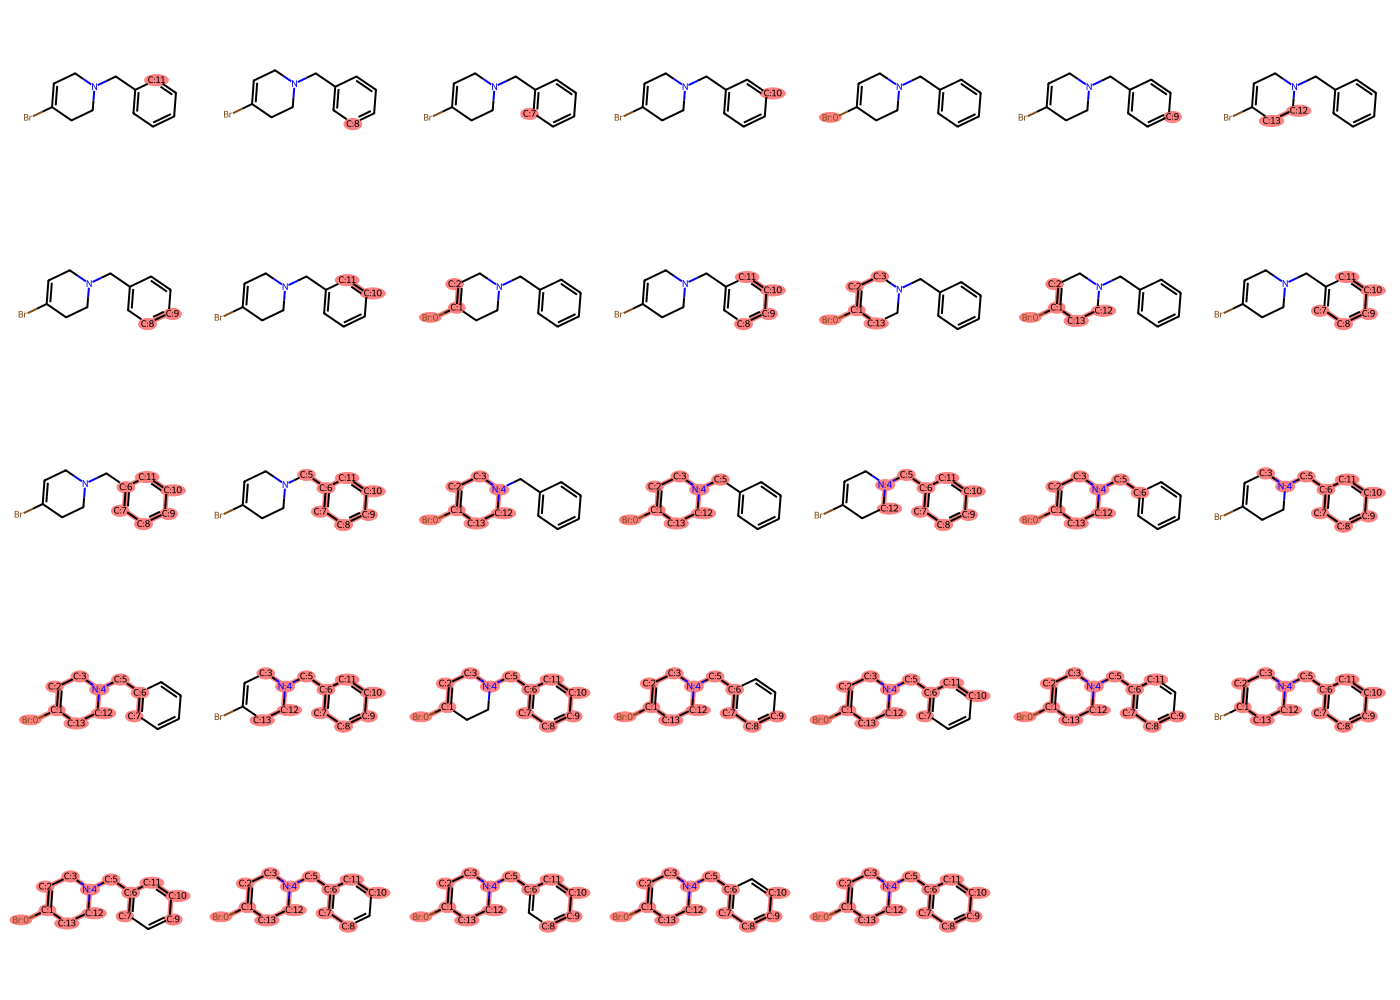

In [184]:
#mol = mol_df.iloc[1]['mol']
#fragments_atom_ids_list = create_fragments(mol, depth=3, set_reorder=True)

img = draw_highlighted_grid(mol, fragments_atom_ids_list[0:40])
img

In [166]:
#from tqdm import tqdm
#for i in tqdm(range(len(mol_df))):
    #mol = mol_df.iloc[i]['mol']
    #fragments_atom_ids_list = create_fragments(mol)
    #mol_df.at[i, 'fragments_atom_ids'] = fragments_atom_ids_list